The Iris dataset is a collection of 150 floral measurements (sepal/petal length & width) for three species of iris flower (setosa, versicolor, virginica).

Our goal is to predict the species of a flower given its measurements.

What is the number of

*   Instances
*   Features
*   Classes

In [ ]:
import sklearn
from sklearn.datasets import load_iris
import numpy as np

dataset = load_iris()

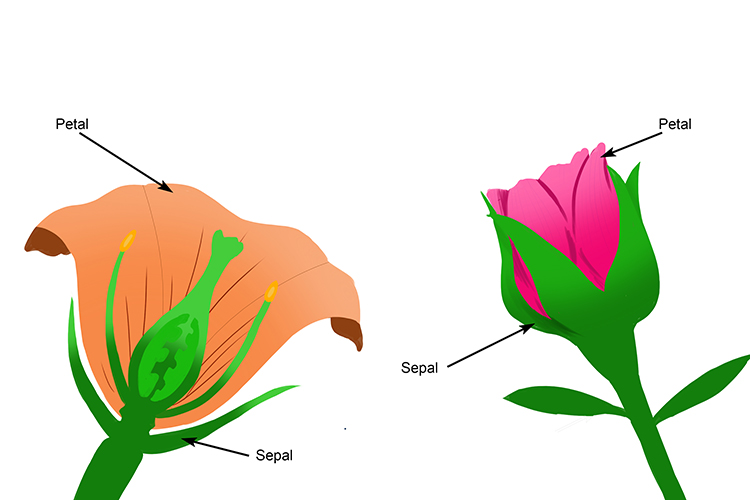

Let's inspect the contents of a dataset object.

In [ ]:
dir(dataset)

['DESCR',
 'data',
 'data_module',
 'feature_names',
 'filename',
 'frame',
 'target',
 'target_names']

['DESCR',
 'data',
 'data_module',
 'feature_names',
 'filename',
 'frame',
 'target',
 'target_names']

In [ ]:
print(f'{dataset.feature_names = }')
print(f'{dataset.target_names = }')

dataset.feature_names = ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
dataset.target_names = array(['setosa', 'versicolor', 'virginica'], dtype='<U10')


By convention, we store the features in a 2D array X and the target values in a integer 1D array y.  


Each row in X describes an example or instance and each column in X contains the value of a feature or attribute. Each element in y contains the index of the class of a given instance such that the instance described by row X[i] belongs to class y[i].

Notice the following:

*   X.shape[0] == y.shape[0]
*   X.shape[1] is the number of features in the data
*   The number of classes is given by np.max(y) + 1

In [ ]:
X = dataset.data
y = dataset.target
print(f'{X.shape = }')
print(f'{y.shape = }')
print(f'{np.max(y) = }')

X.shape = (150, 4)
y.shape = (150,)
np.max(y) = np.int64(2)


# Split dataset

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=5361,stratify=y)

print(f'{X_train.shape = }')
print(f'{X_test.shape = }')
print(f'{y_train.shape = }')
print(f'{y_test.shape = }')

X_train.shape = (120, 4)
X_test.shape = (30, 4)
y_train.shape = (120,)
y_test.shape = (30,)


In [ ]:
for i in range(3):
  print(i,np.sum(y_test==i))
for i in range(3):
  print(i,np.sum(y_train==i))

0 10
1 10
2 10
0 40
1 40
2 40


# Create model (classifier)

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

model = KNeighborsClassifier()

# Evaluate model

## Predict class of test examples

In [ ]:
model.fit(X_train, y_train)
pred = model.predict(X_test)


## Compute accuracy of predictions

In [ ]:
acc = np.mean(pred==y_test)
print(acc)

1.0


# Implement leave-one-out cross validation and evaluate results

In [ ]:
for i in range(X.shape[0]):
  X_test = X[i:i+1]
  ind = np.arange(X.shape[0])!=i
  model.fit(X[ind], y[ind])


# Compare the performance of weighted and unweighted k-nn

# Find the optimal number of neighbors to use